CLASSIFICATION ALGORITHM COMPARISON
          Algorithm  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
                KNN         93.33          94.44       93.33         93.27
        Naive Bayes         96.67          96.97       96.67         96.66
      Decision Tree         93.33          93.33       93.33         93.33
Logistic Regression         93.33          93.33       93.33         93.33
                SVM         96.67          96.97       96.67         96.66
      Random Forest         90.00          90.24       90.00         89.97


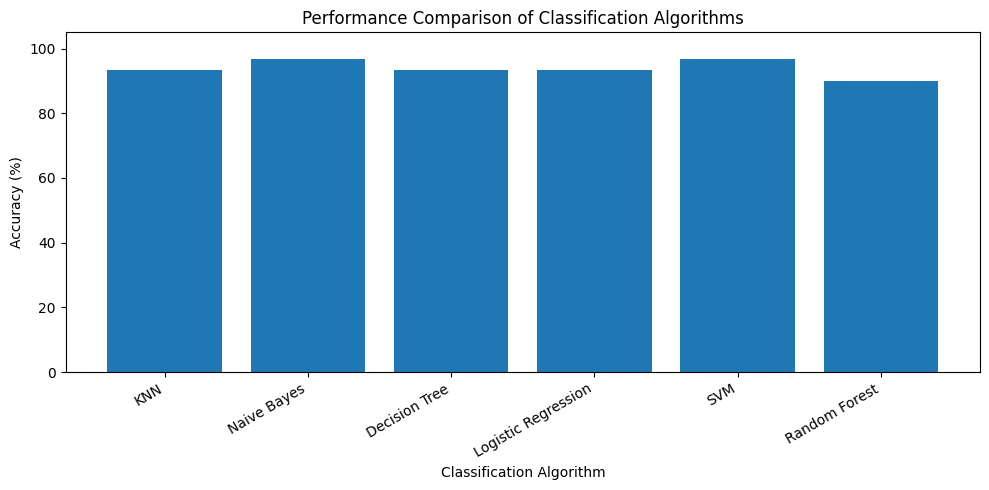


Best Algorithm: Naive Bayes
Best Accuracy: 96.67 %

Program executed successfully!


In [17]:

# Classification Algorithms Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

# 3. Define classification algorithms
models = {
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

# 4. Train and evaluate models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Algorithm": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(
                y_test, predictions,
                average="weighted", zero_division=0
            ) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(
                y_test, predictions,
                average="weighted", zero_division=0
            ) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(
                y_test, predictions,
                average="weighted", zero_division=0
            ) * 100, 2
        )
    })

# 5. Display results
result_df = pd.DataFrame(results)

print("CLASSIFICATION ALGORITHM COMPARISON")
print(result_df.to_string(index=False))

# 6. Plot accuracy comparison
plt.figure(figsize=(10, 5))
plt.bar(result_df["Algorithm"], result_df["Accuracy (%)"])
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy (%)")
plt.title("Performance Comparison of Classification Algorithms")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

# 7. Identify best model
best_model = result_df.loc[
    result_df["Accuracy (%)"].idxmax()
]

print("\nBest Algorithm:", best_model["Algorithm"])
print("Best Accuracy:", best_model["Accuracy (%)"], "%")

print("\nProgram executed successfully!")
